# DSCI 552 — Homework 3

- **Name:** Gina Mao
- **GitHub Username:** ruoxuanm116
- **USC ID:** 8885483334

## Imports

In [1]:
import os
import re
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
RNG_SEED = 552

# Problem 1. Time Series Classification Part 1: Feature Creation/Extraction

## 1(a) Load the AReM data

The data is stored under `../data/AReM/` (relative to this notebook). There are 7 activity folders
(`bending1`, `bending2`, `cycling`, `lying`, `sitting`, `standing`, `walking`) and 88 instances in total.

**Data cleaning.** A few files need minor cleaning, which is handled in the loader below instead of editing the files by hand:

- `bending2/dataset4.csv` is space-delimited instead of comma-delimited;
- some rows in `cycling/dataset9.csv` and `cycling/dataset14.csv` end with an extra trailing comma;
- `sitting/dataset8.csv` has 479 rows instead of 480 (the instance is kept as-is; the features below are summary statistics, so one missing sample does not matter).

The loader skips the `#` header lines, splits each row on commas **or** whitespace, and keeps the first 7 fields (`time` + 6 series).

In [2]:
DATA_DIR = "../data/AReM"
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
COLUMNS = ["time"] + SERIES


def load_instance(path):
    """Read one AReM file robustly (comma or space delimited, trailing commas)."""
    rows = []
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            tokens = [t for t in re.split(r"[,\s]+", line) if t != ""]
            rows.append([float(t) for t in tokens[:7]])
    return pd.DataFrame(rows, columns=COLUMNS)


def file_number(path):
    return int(re.search(r"dataset(\d+)\.csv$", path).group(1))


instances = []   # list of dicts: activity, file number, dataframe
for act in ACTIVITIES:
    files = sorted(glob.glob(f"{DATA_DIR}/{act}/dataset*.csv"), key=file_number)
    for fp in files:
        instances.append({"activity": act, "dataset": file_number(fp), "data": load_instance(fp)})

summary = (pd.DataFrame([{"activity": d["activity"], "rows": len(d["data"])} for d in instances])
             .groupby("activity").agg(n_instances=("rows", "size"), min_rows=("rows", "min"), max_rows=("rows", "max")))
print("Total instances:", len(instances))
summary

Total instances: 88


,n_instances,min_rows,max_rows
activity,,,
bending1,7,480,480
bending2,6,480,480
cycling,15,480,480
lying,15,480,480
sitting,15,479,480
standing,15,480,480
walking,15,480,480


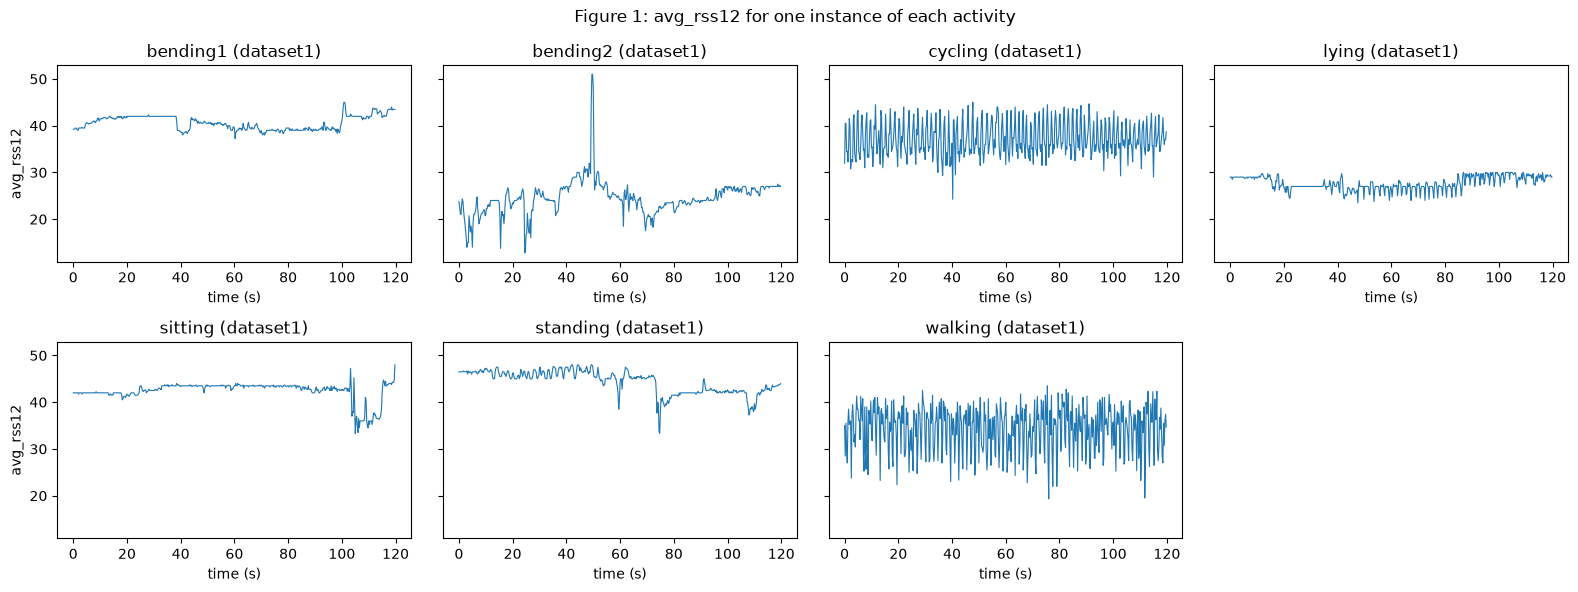

In [3]:
# A quick look at one instance per activity (time series 1: avg_rss12)
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharey=True)
for ax, act in zip(axes.ravel(), ACTIVITIES):
    d = next(i for i in instances if i["activity"] == act)["data"]
    ax.plot(d["time"] / 1000, d["avg_rss12"], lw=0.8)
    ax.set_title(f"{act} (dataset1)")
    ax.set_xlabel("time (s)")
axes[0, 0].set_ylabel("avg_rss12")
axes[1, 0].set_ylabel("avg_rss12")
axes[-1, -1].axis("off")
fig.suptitle("Figure 1: avg_rss12 for one instance of each activity")
plt.tight_layout()
plt.show()

## 1(b) Train / test split

Test data: datasets 1 and 2 in `bending1` and `bending2`, and datasets 1, 2, 3 in every other folder.
Everything else is training data.

In [4]:
def is_test(act, num):
    if act in ("bending1", "bending2"):
        return num in (1, 2)
    return num in (1, 2, 3)

for d in instances:
    d["split"] = "test" if is_test(d["activity"], d["dataset"]) else "train"

split_counts = pd.crosstab(pd.Series([d["activity"] for d in instances], name="activity"),
                           pd.Series([d["split"] for d in instances], name="split"))
split_counts.loc["Total"] = split_counts.sum()
split_counts

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12
Total,19,69


## 1(c) Feature Extraction

### 1(c)i. Time-domain features commonly used in time series classification

Time-domain features are computed directly from the raw samples, without transforming to the frequency domain. Commonly used ones include:

| Category | Features |
|---|---|
| Location / central tendency | mean, median, mode, trimmed mean |
| Extremes | minimum, maximum, range (max − min), peak value, peak-to-peak amplitude |
| Spread / dispersion | variance, standard deviation, interquartile range, mean absolute deviation, coefficient of variation |
| Order statistics | first quartile, third quartile, other percentiles (e.g. 5th, 95th) |
| Shape of the distribution | skewness, kurtosis |
| Energy / magnitude | root mean square (RMS), signal energy (sum of squares), signal magnitude area, mean absolute value |
| Temporal dynamics | zero-crossing rate / mean-crossing rate, autocorrelation at various lags, slope (linear trend), number of peaks, waveform length (sum of absolute first differences), mean of first/second differences |
| Complexity | entropy (sample/approximate entropy), Hjorth parameters (activity, mobility, complexity) |

### 1(c)ii. Extract min, max, mean, median, std, 1st quartile, 3rd quartile

For each of the 6 time series in each of the 88 instances we compute the 7 statistics, giving 42 features.
Column naming follows the assignment: `min1, max1, mean1, median1, std1, 1st_quart1, 3rd_quart1, ..., 3rd_quart6`,
where the number is the index of the time series (1 = avg_rss12, ..., 6 = var_rss23).
Standard deviation uses the sample definition (`ddof=1`). Features are used directly (not normalized).

In [5]:
STATS = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]

def extract_features(series):
    x = np.asarray(series, dtype=float)
    return {
        "min": x.min(),
        "max": x.max(),
        "mean": x.mean(),
        "median": np.median(x),
        "std": x.std(ddof=1),
        "1st_quart": np.percentile(x, 25),
        "3rd_quart": np.percentile(x, 75),
    }

records = []
for k, d in enumerate(instances, start=1):
    row = {"Instance": k}
    for s_idx, s_name in enumerate(SERIES, start=1):
        feats = extract_features(d["data"][s_name])
        for stat in STATS:
            row[f"{stat}{s_idx}"] = feats[stat]
    row["activity"] = d["activity"]
    row["dataset"] = d["dataset"]
    row["split"] = d["split"]
    records.append(row)

features_df = pd.DataFrame(records).set_index("Instance")
FEATURE_COLS = [f"{stat}{i}" for i in range(1, 7) for stat in STATS]
print("Feature table shape (instances x features):", features_df[FEATURE_COLS].shape)
features_df.round(3)

Feature table shape (instances x features): (88, 42)


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,activity,dataset,split
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.625,40.50,1.477,39.25,42.000,0.0,1.30,0.359,0.430,0.323,0.00,0.500,4.00,29.50,19.041,19.250,4.463,16.00,23.250,0.0,7.23,0.833,0.50,0.966,0.000,1.120,27.25,38.25,34.311,35.00,2.188,33.000,36.00,0.00,1.92,0.571,0.43,0.583,0.000,1.300,bending1,1,test
2,38.00,45.67,42.813,42.50,1.436,42.00,43.670,0.0,1.22,0.372,0.470,0.289,0.00,0.500,2.00,29.50,20.097,21.000,3.894,19.00,22.250,0.0,5.76,0.876,0.50,1.047,0.000,1.145,27.67,38.50,33.025,33.00,1.995,32.000,34.50,0.00,3.11,0.571,0.43,0.601,0.000,1.300,bending1,2,test
3,35.00,47.40,43.954,44.33,1.559,43.00,45.000,0.0,1.70,0.426,0.470,0.339,0.00,0.500,6.50,29.75,22.122,23.000,3.031,19.75,24.000,0.0,4.44,0.497,0.43,0.551,0.000,0.830,29.00,38.50,35.588,36.00,2.000,35.362,36.50,0.00,1.79,0.493,0.43,0.514,0.000,0.940,bending1,3,train
4,33.00,47.75,42.180,43.50,3.671,39.15,45.000,0.0,3.00,0.696,0.500,0.631,0.00,1.120,8.50,30.00,22.184,23.000,3.810,20.50,24.372,0.0,5.15,0.990,0.83,0.954,0.430,1.300,20.00,38.67,33.494,35.00,3.849,30.458,36.33,0.00,2.18,0.614,0.50,0.524,0.000,1.000,bending1,4,train
5,33.00,45.75,41.678,41.75,2.243,41.33,42.750,0.0,2.83,0.536,0.500,0.405,0.43,0.710,3.00,28.25,19.007,19.125,4.087,16.50,22.062,0.0,6.42,0.842,0.50,0.929,0.430,1.120,23.67,37.50,29.857,30.00,2.411,28.458,31.25,0.00,1.79,0.383,0.43,0.389,0.000,0.500,bending1,5,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.587,34.25,4.651,30.25,37.000,0.0,14.67,4.577,4.260,2.461,2.87,6.105,7.33,23.25,15.318,15.330,2.970,13.25,17.270,0.0,9.00,3.227,3.10,1.647,2.050,4.260,6.33,25.00,15.892,16.00,3.284,13.730,18.25,0.00,8.32,3.260,3.11,1.640,2.050,4.322,walking,11,train
85,19.75,45.50,34.323,35.25,4.752,31.00,38.000,0.0,13.47,4.456,3.900,2.599,2.49,5.970,6.25,22.25,15.210,15.250,2.711,13.50,17.000,0.0,9.00,3.277,3.11,1.500,2.170,4.390,6.25,23.25,15.550,15.75,3.120,13.500,17.75,0.00,9.67,3.433,3.20,1.733,2.157,4.565,walking,12,train
86,19.50,46.00,34.546,35.25,4.842,31.25,37.812,0.0,12.47,4.372,4.135,2.360,2.49,5.800,7.00,22.67,15.186,15.250,2.758,13.25,17.000,0.0,8.34,3.029,2.86,1.665,1.790,4.110,7.00,22.75,15.760,15.75,2.823,14.000,17.75,0.00,10.00,3.338,3.08,1.657,2.160,4.335,walking,13,train


### 1(c)iii. Standard deviation of each feature and 90% bootstrap confidence intervals

For each of the 42 features we estimate its standard deviation across the 88 instances.
Then we build a **90% percentile bootstrap confidence interval** for that standard deviation:

1. Draw $B = 2000$ bootstrap samples of size 88 (instances sampled with replacement);
2. For every bootstrap sample compute the standard deviation of each feature;
3. The 90% CI is given by the 5th and 95th percentiles of the 2000 bootstrap standard deviations.

In [6]:
X_all = features_df[FEATURE_COLS].to_numpy()
n, p = X_all.shape
B = 2000
rng = np.random.default_rng(RNG_SEED)

boot_idx = rng.integers(0, n, size=(B, n))
boot_std = X_all[boot_idx].std(axis=1, ddof=1)        # shape (B, p)

std_ci = pd.DataFrame({
    "feature": FEATURE_COLS,
    "std_estimate": X_all.std(axis=0, ddof=1),
    "CI_lower_5%": np.percentile(boot_std, 5, axis=0),
    "CI_upper_95%": np.percentile(boot_std, 95, axis=0),
}).set_index("feature")
std_ci.round(4)

,std_estimate,CI_lower_5%,CI_upper_95%
feature,,,
min1,9.5700,8.2529,10.7615
max1,4.3944,3.3631,5.2696
mean1,5.3357,4.6948,5.9134
median1,5.4401,4.7785,6.0125
std1,1.7722,1.5647,1.9468
1st_quart1,6.1536,5.5490,6.6770
3rd_quart1,5.1389,4.3561,5.8383
min2,0.0000,0.0000,0.0000
max2,5.0627,4.6387,5.3949


In [7]:
# Cross-check one feature with scipy's built-in bootstrap
res = stats.bootstrap((features_df["mean1"].to_numpy(),), lambda x: np.std(x, ddof=1),
                      confidence_level=0.90, n_resamples=2000, method="percentile",
                      random_state=RNG_SEED)
print("scipy.stats.bootstrap 90% CI for std(mean1):",
      np.round([res.confidence_interval.low, res.confidence_interval.high], 4))
print("manual bootstrap 90% CI for std(mean1):      ",
      std_ci.loc["mean1", ["CI_lower_5%", "CI_upper_95%"]].round(4).tolist())

scipy.stats.bootstrap 90% CI for std(mean1): [4.7033 5.8782]
manual bootstrap 90% CI for std(mean1):       [4.6948, 5.9134]


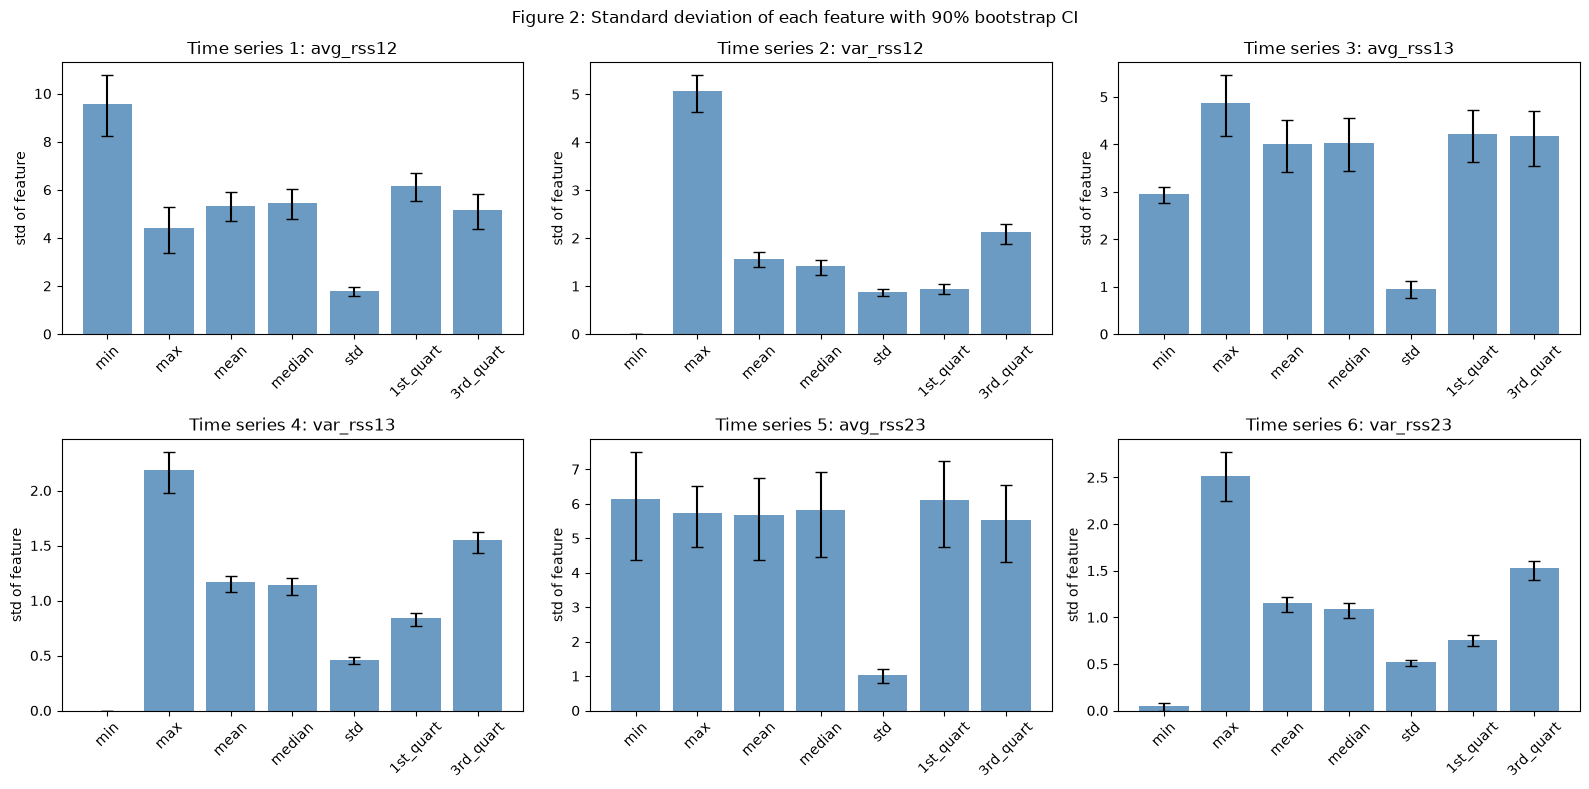

In [8]:
# Visualize the estimates and CIs, one panel per time series
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, ax in enumerate(axes.ravel(), start=1):
    sub = std_ci.loc[[f"{s}{i}" for s in STATS]]
    yerr = np.vstack([sub["std_estimate"] - sub["CI_lower_5%"], sub["CI_upper_95%"] - sub["std_estimate"]])
    ax.bar(STATS, sub["std_estimate"], color="steelblue", alpha=0.8)
    ax.errorbar(STATS, sub["std_estimate"], yerr=yerr, fmt="none", ecolor="black", capsize=4)
    ax.set_title(f"Time series {i}: {SERIES[i-1]}")
    ax.set_ylabel("std of feature")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Figure 2: Standard deviation of each feature with 90% bootstrap CI")
plt.tight_layout()
plt.show()

### 1(c)iv. Selecting the three most important time-domain features

To support the choice with evidence, I measure how well each type of statistic separates the 7 activities using the
**one-way ANOVA F-statistic** on the **training set only** (so the test set is not used for any decision).
A larger F means the between-activity differences are large relative to within-activity variation.
I compute F for each of the 42 features and then average over the 6 time series for each statistic type.

In [9]:
train_df = features_df[features_df["split"] == "train"]

f_scores = {}
for col in FEATURE_COLS:
    groups = [g[col].to_numpy() for _, g in train_df.groupby("activity")]
    f_scores[col] = stats.f_oneway(*groups).statistic

f_table = pd.DataFrame(
    [[f_scores[f"{s}{i}"] for i in range(1, 7)] for s in STATS],
    index=STATS, columns=[f"ts{i}" for i in range(1, 7)])
f_table["mean_F"] = f_table.mean(axis=1)
f_table["median_F"] = f_table.iloc[:, :6].median(axis=1)
f_table = f_table.sort_values("mean_F", ascending=False)
print("NaN means the feature is constant (min2 and min4 are 0 for every instance), so it carries no information.")
f_table.round(2)

NaN means the feature is constant (min2 and min4 are 0 for every instance), so it carries no information.


,ts1,ts2,ts3,ts4,ts5,ts6,mean_F,median_F
mean,15.85,900.16,26.36,651.76,33.43,581.45,368.17,307.44
3rd_quart,8.54,807.05,28.11,561.90,32.24,664.78,350.44,297.07
median,17.49,477.01,19.41,800.79,28.64,563.13,317.75,252.83
1st_quart,21.38,265.46,21.19,244.82,25.49,346.34,154.11,135.16
std,9.10,360.89,15.22,128.62,7.78,133.39,109.17,71.92
max,1.51,47.73,31.69,29.33,36.95,32.96,30.03,32.33
min,10.97,NaN,22.71,NaN,24.10,0.78,14.64,16.84


The raw F values of the variance series (ts2, ts4, ts6) are much larger than those of the average series, so the column means
are dominated by them. To compare statistic types on an equal footing, I also rank the 7 statistics **within each time series**
(1 = largest F) and average the ranks.

In [10]:
rank_table = f_table.iloc[:, :6].rank(ascending=False)
rank_table["avg_rank"] = rank_table.mean(axis=1)
rank_table.sort_values("avg_rank")

,ts1,ts2,ts3,ts4,ts5,ts6,avg_rank
mean,3.0,1.0,3.0,2.0,2.0,2.0,2.166667
3rd_quart,6.0,2.0,2.0,3.0,3.0,1.0,2.833333
median,2.0,3.0,6.0,1.0,4.0,3.0,3.166667
1st_quart,1.0,5.0,5.0,4.0,5.0,4.0,4.000000
max,7.0,6.0,1.0,6.0,1.0,6.0,4.500000
min,4.0,NaN,4.0,NaN,6.0,7.0,5.250000
std,5.0,4.0,7.0,5.0,7.0,5.0,5.500000


Statistics that are almost perfectly correlated with each other carry the same information. Below is the correlation
between the mean and each other statistic, averaged over the average-RSS series (1, 3, 5) and the variance series (2, 4, 6),
on the training set.

In [11]:
def avg_corr(a, b, idx):
    cs = []
    for i in idx:
        x, y = train_df[f"{a}{i}"], train_df[f"{b}{i}"]
        if x.std() > 0 and y.std() > 0:
            cs.append(np.corrcoef(x, y)[0, 1])
    return np.mean(cs) if cs else np.nan

redundancy = pd.DataFrame(
    {"corr with mean (avg series 1,3,5)": [avg_corr("mean", s, [1, 3, 5]) for s in STATS if s != "mean"],
     "corr with mean (var series 2,4,6)": [avg_corr("mean", s, [2, 4, 6]) for s in STATS if s != "mean"]},
    index=[s for s in STATS if s != "mean"])
redundancy.round(2)

,"corr with mean (avg series 1,3,5)","corr with mean (var series 2,4,6)"
min,0.73,0.18
max,0.72,0.85
median,0.99,1.00
std,-0.21,0.97
1st_quart,0.97,0.99
3rd_quart,0.96,1.00


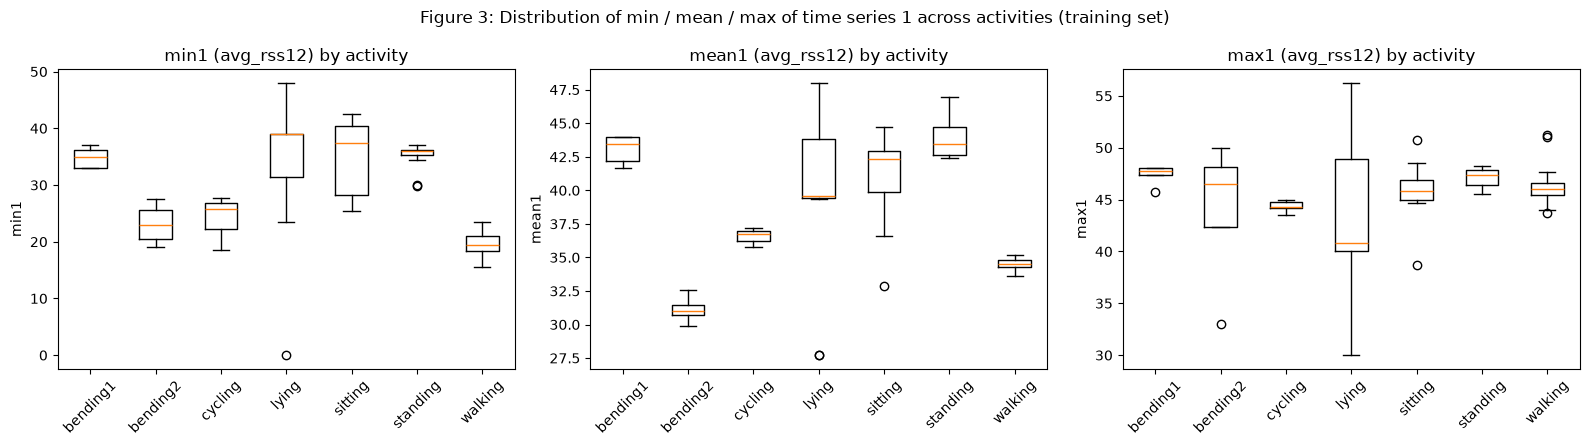

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, stat in zip(axes, ["min", "mean", "max"]):
    data = [train_df.loc[train_df["activity"] == a, f"{stat}1"] for a in ACTIVITIES]
    ax.boxplot(data)
    ax.set_xticks(range(1, len(ACTIVITIES) + 1), ACTIVITIES, rotation=45)
    ax.set_title(f"{stat}1 (avg_rss12) by activity")
    ax.set_ylabel(f"{stat}1")
fig.suptitle("Figure 3: Distribution of min / mean / max of time series 1 across activities (training set)")
plt.tight_layout()
plt.show()

**Answer to 1(c)iv.** I select **min, mean, and max** as the three most important time-domain features.

Reasoning, based on the tables above (training set only):

- **mean** has the best average rank of all 7 statistics (it is in the top 3 for every time series), so it is the strongest
  single feature for separating activities.
- **median, 1st quartile and 3rd quartile** also rank well, but their correlation with the mean is about 0.96–1.00. They
  measure the same thing (the level of the signal), so adding them on top of the mean adds almost no new information.
- After removing that redundant group, the remaining statistics are **max, min and std**. max (avg rank ≈ 4.5) and
  min (≈ 5.3) rank higher than std (≈ 5.5). max is actually the best statistic for time series 3 and 5, and min is far less
  correlated with the mean than the quartiles are, so both add information that the mean does not.
- std is the weakest on average and, for the variance series, it is almost perfectly correlated with the mean (≈ 0.97),
  so it is the least useful.
- Caveat: min2 and min4 are 0 for every instance (a variance can always hit 0 within 2 minutes), so for those two series
  min carries no information. min is still useful for the average-RSS series (1, 3, 5), which is where Figure 3 shows clear
  separation (min1 is high for bending1, lying, sitting and standing, and clearly lower for bending2, cycling and walking).

Together, min, mean and max describe both the level and the range of each signal with low redundancy and are easy to
interpret, which suits the logistic regression models in Part 2.

# Problem 2. ISLR 3.7.4

Setting: $n = 100$ observations, one predictor, a single quantitative response. We fit a linear regression
$Y = \beta_0 + \beta_1 X + \epsilon$ and a cubic regression $Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \epsilon$.

**(a) True relationship is linear — training RSS.**
The training RSS of the **cubic regression will be lower (or at least no higher)** than that of the linear regression.
The linear model is nested inside the cubic model (set $\beta_2 = \beta_3 = 0$), and least squares minimizes training RSS,
so the cubic fit can always do at least as well on the training data. In practice the extra terms fit some of the noise,
so its training RSS is typically strictly smaller.

**(b) True relationship is linear — test RSS.**
We would expect the **linear regression to have the lower test RSS**. The linear model matches the true form, so it has
essentially no bias, while the cubic model adds two unnecessary parameters that increase variance (it overfits the noise
in the training set). That extra variance shows up as a higher test error. (With a particular small sample this is not
guaranteed, but it is what we expect on average.)

**(c) True relationship is non-linear (unknown how far) — training RSS.**
The **cubic regression will have lower (or equal) training RSS**, for exactly the same reason as in (a): the models are nested
and the cubic model is more flexible. This holds no matter what the true relationship is.

**(d) True relationship is non-linear — test RSS.**
**There is not enough information to tell.** If the true relationship is only slightly non-linear (close to linear),
the linear model may still win because the cubic's added variance outweighs its small reduction in bias.
If the relationship is far from linear, the cubic model's reduction in bias will dominate and it will likely have the lower test RSS.
It depends on the bias–variance trade-off, i.e. on how non-linear the truth is.

### Simulation to illustrate the answers (optional)

A quick simulation with $n = 100$ training points and a large test set, repeated 500 times.

In [13]:
def sim(true_f, reps=500, n_train=100, n_test=1000, sigma=1.0, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    out = np.zeros((reps, 4))  # train_lin, train_cub, test_lin, test_cub
    for r in range(reps):
        x = rng.uniform(-2, 2, n_train); y = true_f(x) + rng.normal(0, sigma, n_train)
        xt = rng.uniform(-2, 2, n_test); yt = true_f(xt) + rng.normal(0, sigma, n_test)
        for j, deg in enumerate([1, 3]):
            coef = np.polyfit(x, y, deg)
            out[r, j] = np.sum((y - np.polyval(coef, x)) ** 2)
            out[r, 2 + j] = np.sum((yt - np.polyval(coef, xt)) ** 2) * n_train / n_test  # scaled to 100 points
    return out

scenarios = {
    "(a)/(b) linear truth": lambda x: 1 + 2 * x,
    "(c)/(d) slightly non-linear": lambda x: 1 + 2 * x + 0.1 * x ** 2,
    "(c)/(d) strongly non-linear": lambda x: 1 + 2 * x + 1.5 * x ** 3,
}
rows = []
for name, f in scenarios.items():
    o = sim(f)
    rows.append({"scenario": name,
                 "train RSS linear": o[:, 0].mean(), "train RSS cubic": o[:, 1].mean(),
                 "test RSS linear": o[:, 2].mean(), "test RSS cubic": o[:, 3].mean(),
                 "% reps cubic train RSS <= linear": 100 * np.mean(o[:, 1] <= o[:, 0] + 1e-9),
                 "% reps cubic test RSS < linear": 100 * np.mean(o[:, 3] < o[:, 2])})
pd.DataFrame(rows).set_index("scenario").round(2)

,train RSS linear,train RSS cubic,test RSS linear,test RSS cubic,% reps cubic train RSS <= linear,% reps cubic test RSS < linear
scenario,,,,,,
(a)/(b) linear truth,98.54,96.5,102.28,104.53,100.0,7.8
(c)/(d) slightly non-linear,99.77,96.5,103.74,104.53,100.0,46.0
(c)/(d) strongly non-linear,419.91,96.5,437.80,104.53,100.0,100.0


The simulation agrees with the answers above: the cubic fit always has the lower training RSS; with a linear truth the linear fit
has slightly lower test RSS on average; with a slightly non-linear truth the two are close; with a strongly non-linear truth
the cubic fit has a much lower test RSS.

# References

- AReM dataset: https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29
- James, Witten, Hastie, Tibshirani — *An Introduction to Statistical Learning*, Ch. 3 (Linear Regression) and Ch. 5.2 (The Bootstrap)
- SciPy `scipy.stats.bootstrap`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html
- SciPy `scipy.stats.f_oneway`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html
- Efron, B., Tibshirani, R. — *An Introduction to the Bootstrap* (percentile confidence intervals)